# 원본 Process 로그로 선택한 n시간 분석하기

**입력 로그 컬럼은 그대로 유지한다.** 최근 1·4·8·12·24시간 중 선택한 구간만 잘라 내부에서 5분씩 집계한다. 1시간은 12개, 24시간은 288개 집계점이다. 과거 감시 배치나 이후 로그는 보지 않는다.

정상 학습으로 미리 만든 기준 통계는 사용한다. 이는 현재 감시 구간 밖의 실행 로그를 매번 추가로 조회한다는 뜻이 아니다. 미래의 실행 시간을 예측하는 모델이 아니라, 선택한 구간이 정상 패턴과 다른지 판단하는 회고적 이상탐지다.

이 노트북은 최신 모델 하나만 설명한다. 내부 해상도가 달라진 **새 반합성 평가**이므로, 이전 시간당 1점 평가와 성능 차이를 직접 비교하면 안 된다.

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
while not (root/'code/long_term_anomaly').is_dir() and root.parent!=root:
    root=root.parent
sys.path.insert(0,str(root/'code'))
import pandas as pd
from IPython.display import display,Image,Markdown
from long_term_anomaly.common import read_json
from long_term_anomaly.five_minute.localized import OUT
from long_term_anomaly.five_minute.serialization import load_portable
from long_term_anomaly.five_minute.report import TASKS,HOURS
bank=load_portable()
current=read_json(OUT/'confirmation_results.json')['results']
def table(metric_group='median'):
    rows=[]
    for h in HOURS:
        r=current[str(h)]
        rows.append({'분석 구간':f'{h}시간',**{k:r[metric_group][k] for k in ('accuracy','precision','recall','f1')},
                     '최대 시나리오 오탐률':r['maximum_scenario_fpr']})
    return pd.DataFrame(rows).set_index('분석 구간')
display(table().style.format('{:.2%}'))

,accuracy,precision,recall,f1,최대 시나리오 오탐률
분석 구간,,,,,
1시간,92.90%,80.47%,76.39%,76.96%,4.10%
4시간,94.89%,96.73%,69.97%,80.78%,0.66%
8시간,95.52%,98.01%,73.12%,83.43%,0.45%
12시간,95.56%,97.98%,73.41%,83.64%,0.36%
24시간,95.23%,98.32%,71.23%,82.24%,0.32%


## 1. 이 성능표는 무엇을 의미하나?

여섯 시나리오에서 Accuracy·Precision·Recall·F1을 각각 구한 뒤, **각 지표의 중앙값**을 계산했다. 모든 개별 시나리오가 중앙값만큼 좋다는 뜻은 아니다. 아래에서 약한 시나리오까지 모두 보여준다.

Accuracy는 전체 시간 중 맞힌 비율, Precision은 경보 중 실제 이상인 비율, Recall은 이상 시간 중 찾아낸 비율이다. F1은 Precision과 Recall의 균형을 보는 값이다. 오탐률은 **정상 시간 중 잘못 경보한 비율**이며, 1−Precision과 다르다.

표본은 최종 모델을 고정한 뒤 새로 생성한 576개 사례다. 정상·이상 쌍을 시나리오마다 48개씩 만들었다. 같은 생성 방식을 사용한 새 표본이며 실제 장애 정답을 확보한 평가는 아니다.

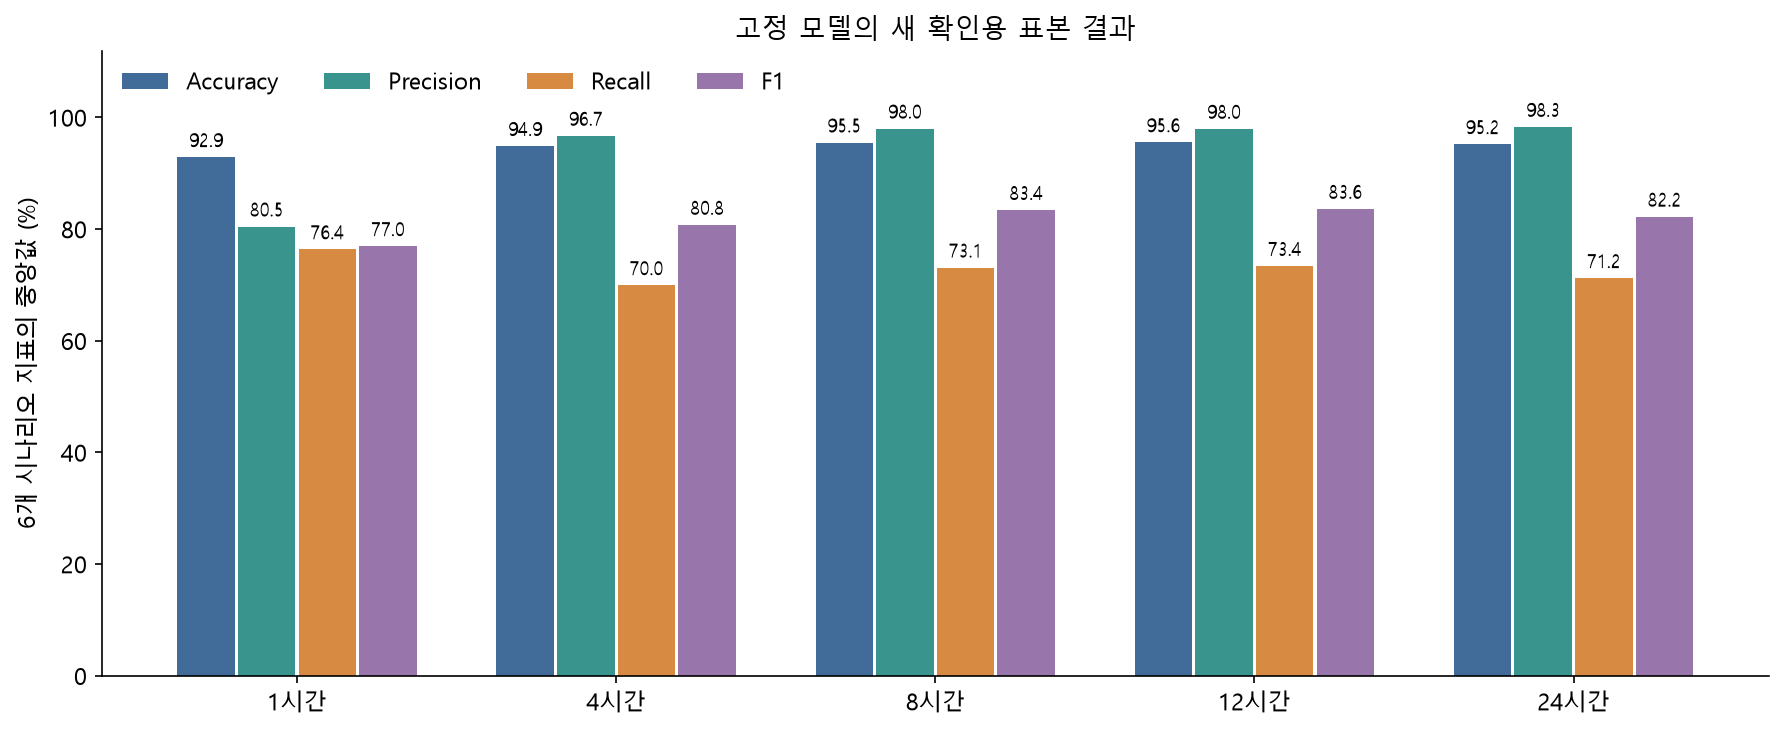

In [2]:
display(Image(filename=str(OUT/'figures/median_metrics.png')))

## 2. 원본의 어떤 컬럼을 쓰나?

| 원본 값 | 내부에서 만드는 값 | 뜻 |
|---|---|---|
| `adapterType`, `processId` | 비교 기준을 찾는 집단 키 | ID 문자열 자체를 숫자 피처로 인코딩하지 않음 |
| `startTime` | 5분 구간별 Process 실행 횟수 | Transaction 수나 `totalCount` 합계가 아님 |
| `startTime`, `endTime` | 완료 실행의 `log1p(소요시간 ms)` 평균 | 선택 구간 종료까지 완료가 확인된 실행만 사용 |
| `totalCount` | 실행당 `log1p(처리 건수)` 평균 | 한 번 실행하면서 처리한 데이터 건수 |

미리 검토한 정상 참고 구간 28일에서 시간대별 기준, 변동 폭, 인접 구간의 상관관계를 만든다. 선택한 구간에서는 평소 대비 수준 차이, 변동성, 앞·뒤 차이, 추세 등을 계산한다. **실행 횟수와 처리 건수는 서로 다른 값이다.**

수집이 정상임을 확인한 구간에서만 ‘로그 없음’을 0건으로 처리한다. 수집 여부를 모르거나 수집 장애가 있으면 판단 불가로 남긴다. 0건 구간에 소요시간 0을 만들어 넣지 않는다.

## 3. 모델은 어떻게 정상과 비교하나?

기본 모델은 정상 분포의 상단 꼬리에서 현재 통계가 얼마나 드문지 계산하는 **통계 기반 시간창 모델**이다. IF·K-means·LOF 모델을 대체해 재학습한 것이 아니라, 장기 분석용 별도 모델이다.

1시간은 해당 집단의 과거 정상 1시간 구간 672개와 먼저 비교하고, 공통 정상 학습 분포로 다시 보정한다. 집단마다 정상 변동성이 다른 점을 줄이기 위한 통계표이며, 집단마다 별도 ML 모델을 학습하는 구조가 아니다.

1시간 모드는 개발셋에서 도움이 적었던 처리 건수·하락 변동성·미세 추세 피처의 경보 가중치를 0으로 선택했다. **1시간 모드가 4~7일의 추세 전체를 직접 읽는 것은 아니다.** 현재 1시간의 지연 수준 등이 정상 기준과 달라졌는지를 본다. 아래가 최종 1시간 모델에서 실제 경보에 쓰는 피처다.

In [3]:
cfg=bank.settings[1]
rows=[{'실제 사용 피처':n,'가중치':w} for n,w in zip(bank.models[1].feature_names,cfg['weights']) if w>0]
display(pd.DataFrame(rows))
display(Markdown('`mean_up/down`: 정상 대비 평균 증가/감소 · `variability_up`: 변동 폭 증가 · `energy`: 기준에서 떨어진 정도 · `innovation_energy`: 정상적인 인접 상관관계로 설명되지 않는 변화'))

,실제 사용 피처,가중치
0,count:mean_up,1.00
1,count:mean_down,1.00
2,duration:mean_up,1.00
3,duration:mean_down,0.25
4,duration:variability_up,0.25
5,duration:energy,0.25
6,duration:innovation_energy,0.25


`mean_up/down`: 정상 대비 평균 증가/감소 · `variability_up`: 변동 폭 증가 · `energy`: 기준에서 떨어진 정도 · `innovation_energy`: 정상적인 인접 상관관계로 설명되지 않는 변화

## 4. 긴 구간의 경보가 정상 시간에 번지는 것을 막기

4·8·12·24시간 모드는 **선택한 전체 구간의 이상 근거**와 **그 안의 해당 1시간 근거**가 모두 기준을 넘을 때만 그 시간에 경보한다. 예를 들어 24시간 중 마지막 3시간만 느린데, 앞의 정상 21시간까지 모두 이상이라고 하지 않도록 한 것이다.

두 기준을 통과한 정도 중 작은 값을 최종 점수로 사용한다. 따라서 긴 구간 모드의 최종 경보 기준은 0 초과다. 점수는 장애 확률이 아니다. 수치 기준은 정상 보정·개발 데이터에서 고정했으며 확인용 표본의 정답으로 바꾸지 않았다.

첫 native 평가에서 긴 구간 경보가 번지는 문제를 발견해 구조를 바꿨다. 그러므로 그 최초 평가는 더 이상 블라인드가 아니다. 위 성능표는 **구조 수정까지 끝난 뒤 모델을 고정하고 새로 생성한 확인용 표본**의 결과다.

,구간,전체 구간 기준,구간 내 1시간 기준,최종 기준
0,1시간,4.318844,4.318844,원 점수 > 기준
1,4시간,6.024564,4.318844,두 기준 통과 정도의 최솟값 > 0
2,8시간,5.499029,4.318844,두 기준 통과 정도의 최솟값 > 0
3,12시간,6.218011,4.318844,두 기준 통과 정도의 최솟값 > 0
4,24시간,6.678570,4.318844,두 기준 통과 정도의 최솟값 > 0


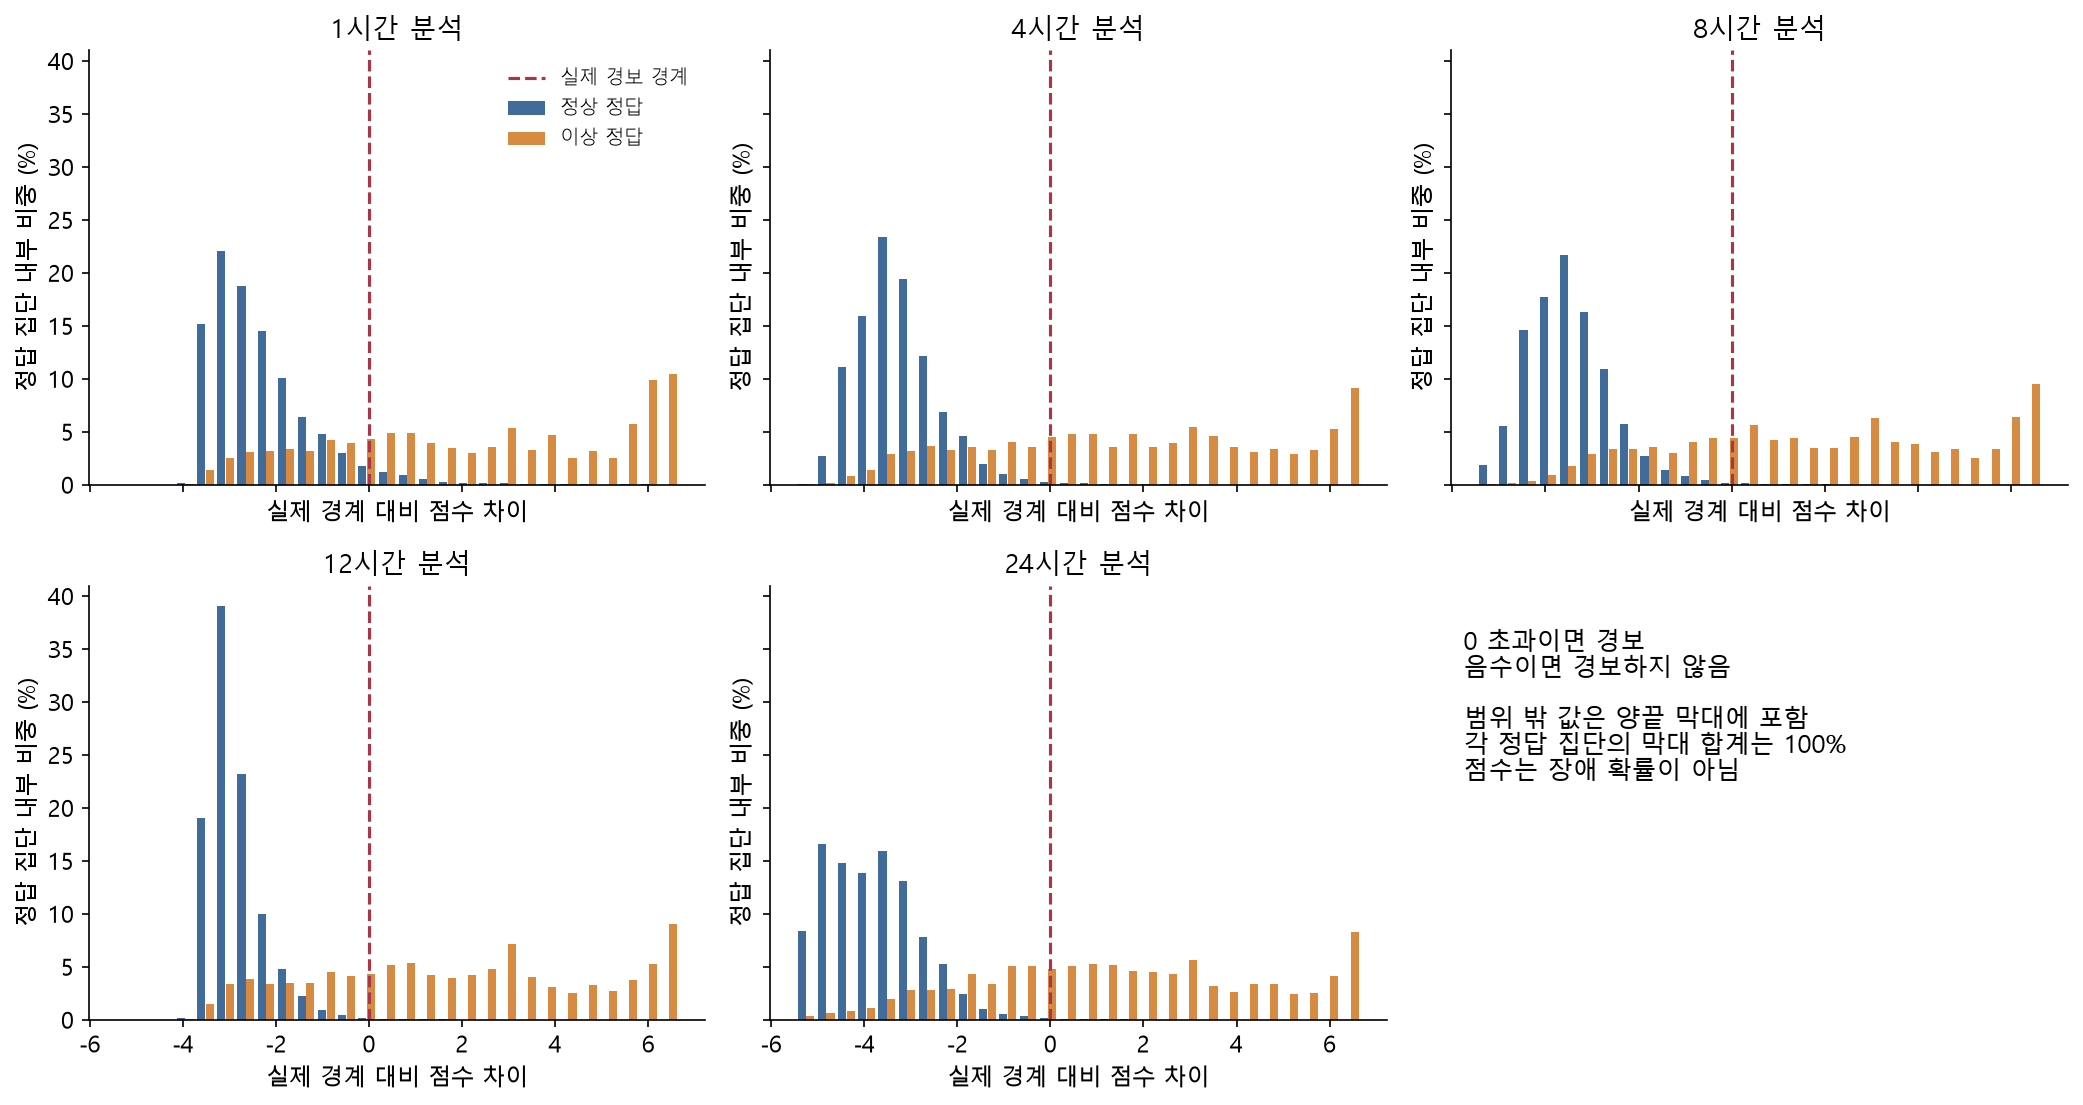

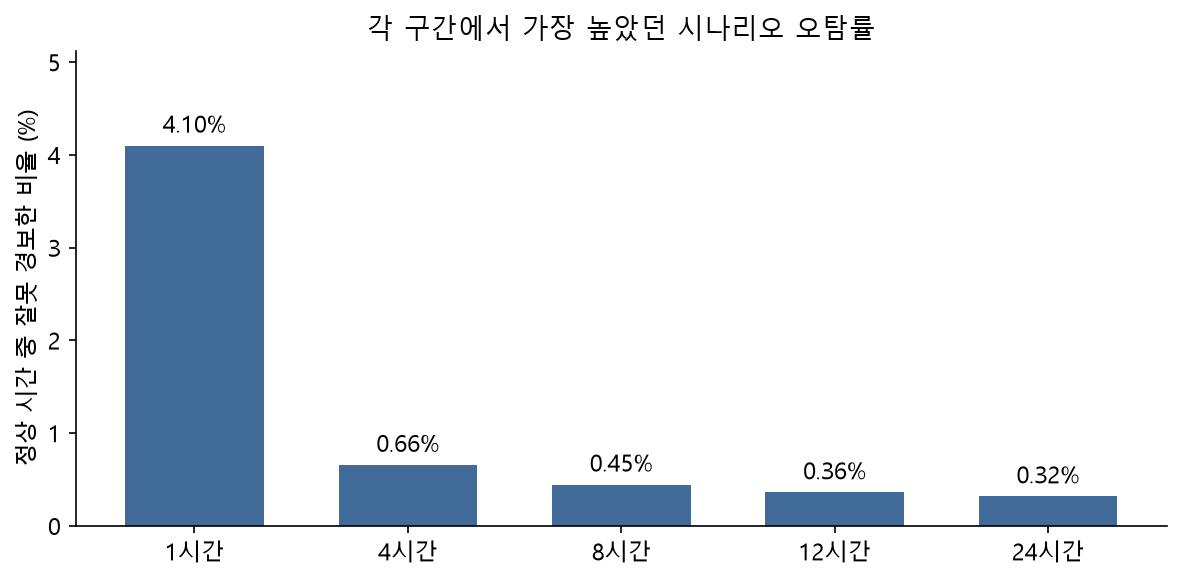

In [4]:
display(pd.DataFrame([{'구간':f'{h}시간','전체 구간 기준':bank.settings[h]['threshold'],
    '구간 내 1시간 기준':bank.settings[1]['threshold'], '최종 기준':'원 점수 > 기준' if h==1 else '두 기준 통과 정도의 최솟값 > 0'}
    for h in HOURS]))
display(Image(filename=str(OUT/'figures/alarm_margin_distribution.png')))
display(Image(filename=str(OUT/'figures/maximum_false_positive_rate.png')))

## 5. 어느 시나리오에서 잘 찾고 놓치나?

| 시나리오 | 만든 변화 |
|---|---|
| 지속 지연 | 3~6일 동안 소요시간 수준 증가 |
| 점진적 악화 | 4~7일 동안 소요시간을 조금씩 증가 |
| 지속 폭주 | 3~6일 동안 Process 실행 횟수 증가 |
| 지속 입력 감소 | 수집은 정상인 상태로 실행 횟수 감소 |
| 일주기 패턴 변화 | 일주일 동안 시간대별 실행 패턴 변경 |
| 변동성 증가 | 평균보다 소요시간의 들쭉날쭉함 증가 |

모델이 경보와 함께 이 시나리오 이름을 정답처럼 분류하는 것은 아니다. 시나리오는 평가 정답의 분류이며 실제 출력은 이상 점수와 통계적 근거다. 약한 초기 악화나 바뀐 일주기 패턴이 정상 수준을 지나가는 시간도 정답에서 제외하지 않았다.

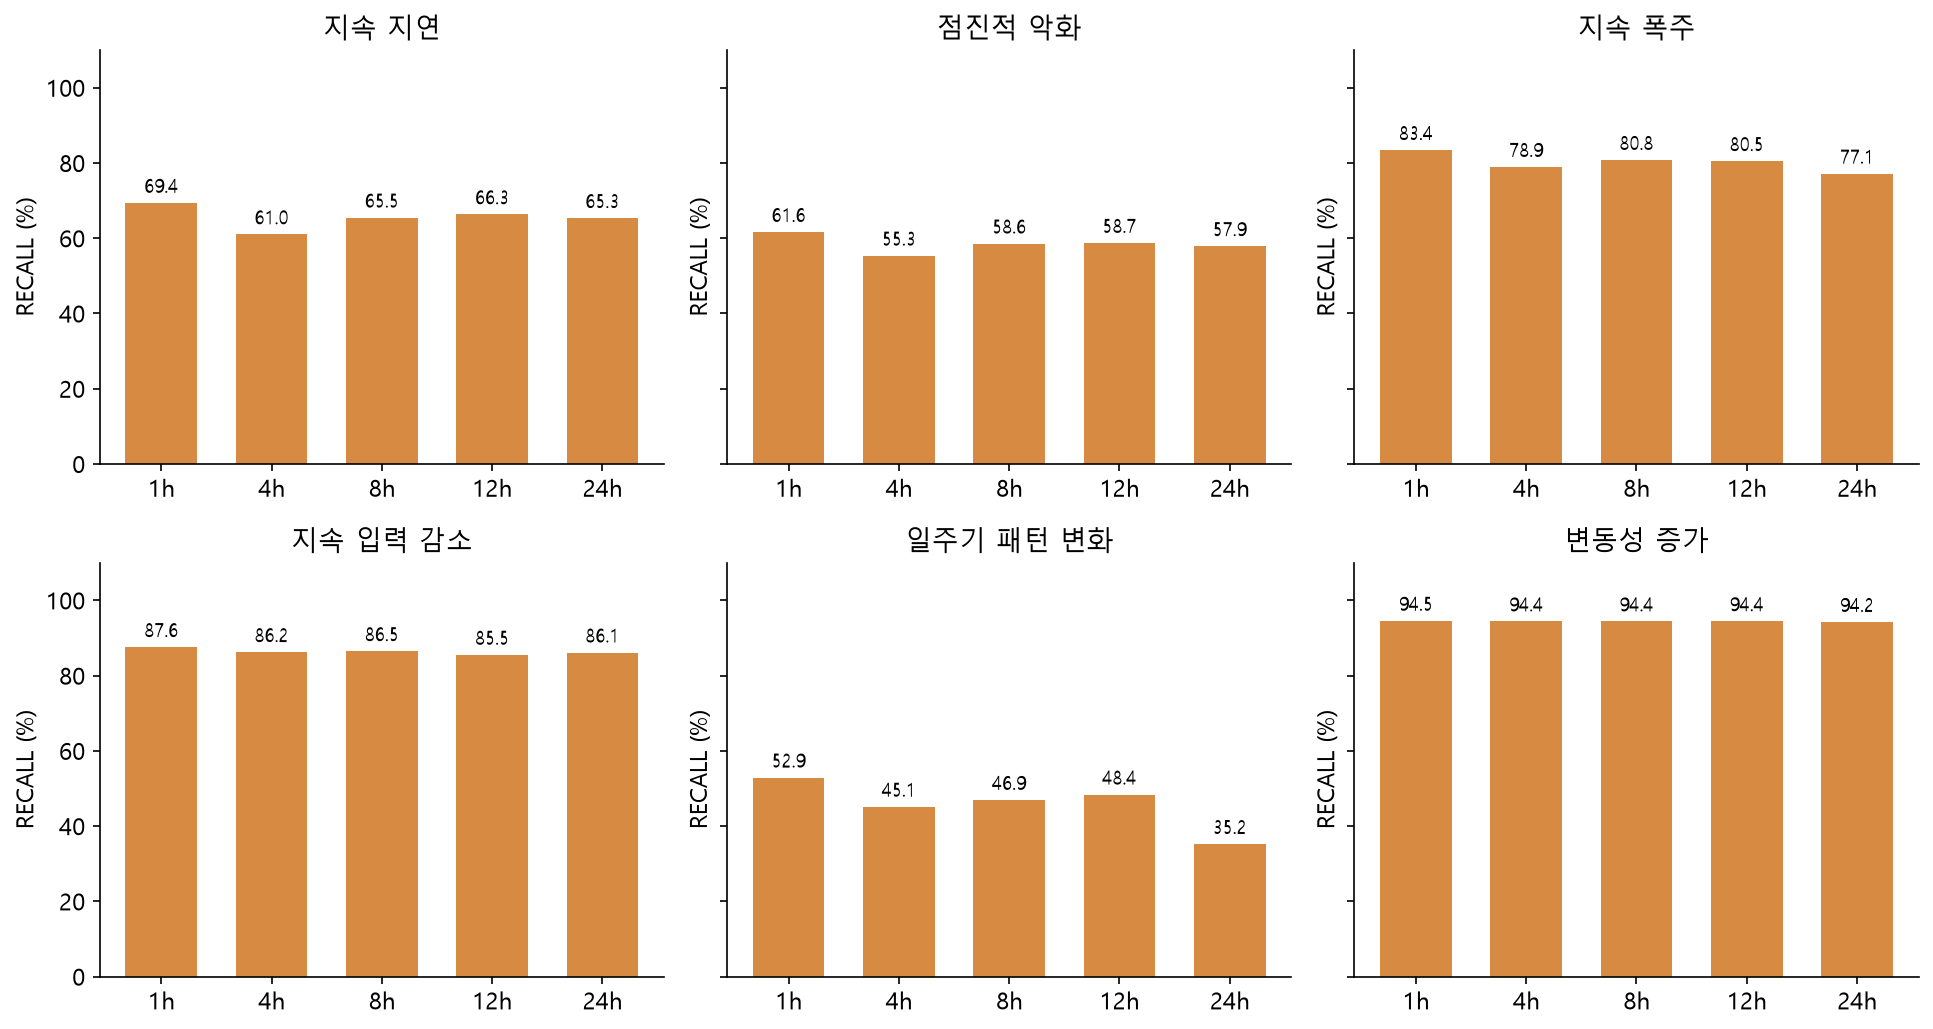

### 시나리오별 PRECISION

,1시간,4시간,8시간,12시간,24시간
지속 지연,76.31%,96.48%,97.62%,97.71%,97.47%
점진적 악화,79.82%,96.98%,98.18%,98.66%,99.51%
지속 폭주,79.17%,96.46%,97.84%,97.69%,97.79%
지속 입력 감소,82.09%,97.19%,98.42%,98.15%,98.58%
일주기 패턴 변화,81.13%,95.81%,97.23%,97.80%,98.05%
변동성 증가,83.52%,98.43%,99.28%,99.18%,98.88%


### 시나리오별 RECALL

,1시간,4시간,8시간,12시간,24시간
지속 지연,69.37%,61.01%,65.45%,66.34%,65.33%
점진적 악화,61.64%,55.34%,58.56%,58.73%,57.87%
지속 폭주,83.41%,78.92%,80.78%,80.48%,77.14%
지속 입력 감소,87.55%,86.22%,86.46%,85.51%,86.11%
일주기 패턴 변화,52.87%,45.12%,46.93%,48.35%,35.21%
변동성 증가,94.54%,94.37%,94.37%,94.42%,94.23%


### 시나리오별 F1

,1시간,4시간,8시간,12시간,24시간
지속 지연,72.68%,74.75%,78.36%,79.02%,78.23%
점진적 악화,69.56%,70.47%,73.36%,73.63%,73.18%
지속 폭주,81.23%,86.81%,88.50%,88.25%,86.24%
지속 입력 감소,84.73%,91.38%,92.06%,91.39%,91.92%
일주기 패턴 변화,64.02%,61.35%,63.30%,64.71%,51.82%
변동성 증가,88.69%,96.35%,96.76%,96.74%,96.50%


In [5]:
display(Image(filename=str(OUT/'figures/scenario_recall.png')))
for metric in ('precision','recall','f1'):
    display(Markdown(f'### 시나리오별 {metric.upper()}'))
    f=pd.DataFrame({f'{h}시간':{TASKS[t]:current[str(h)]['scenarios'][t][metric] for t in TASKS} for h in HOURS})
    display(f.style.format('{:.2%}'))

긴 구간 모델은 현재 1시간의 변화가 작아도 전체 구간의 수준·변동을 볼 수 있다. 다만 최종 경보에는 해당 시간의 근거도 요구하므로, 긴 구간일수록 Recall이 무조건 높아지지는 않는다. 반대로 고립된 정상 요동을 억제하면서 Precision과 오탐률이 개선될 수 있다.

일주기 변화와 악화 초기처럼 변화가 약한 구간은 여전히 놓친다. 중앙값을 만족했다는 이유로 모든 시나리오가 해결되었다고 해석하면 안 된다. 아래는 중앙값과 다른 **전체 관측 시간을 합친 통합 지표**다.

In [6]:
display(table('pooled').style.format('{:.2%}'))

,accuracy,precision,recall,f1,최대 시나리오 오탐률
분석 구간,,,,,
1시간,91.84%,80.52%,72.71%,76.41%,4.10%
4시간,93.74%,96.98%,67.71%,79.74%,0.66%
8시간,94.24%,98.17%,69.65%,81.49%,0.45%
12시간,94.31%,98.24%,69.96%,81.72%,0.36%
24시간,93.67%,98.44%,66.24%,79.19%,0.32%


## 6. 실제 입력과 운영 연결

```python
from long_term_anomaly.five_minute.bank import load_bank
from long_term_anomaly.raw_windows import ProcessWindowService, CollectionCoverage

bank = load_bank('reports/long_term_anomaly/five_minute_localized/models_portable.joblib')
service = ProcessWindowService(bank)
# 정상 참고 데이터는 별도 검토 후 한 번 통계화하고 재사용
references = service.prepare_reference(reviewed_normal_processes,
    end=normal_end, coverage=collector_coverage)
result = service.predict_processes(process_records,
    references=references, window_end=now,
    analysis_hours=4, coverage=collector_coverage)
```

`process_records`는 기존 Process 컬럼의 CSV/JSON/DataFrame이다. 5분 집계 CSV를 외부에서 새로 만들어 전달할 필요가 없다. 수집 상태는 별도 운영 메타데이터이며, CSV의 첫·마지막 시각만으로 정상 수집이라고 추정하지 않는다.

API는 선택 구간이 끝난 뒤 결과를 낸다. 정상 참고 통계는 자동 갱신하지 않고, 이전 감시 데이터나 경보 상태를 이어받지 않는다. 새로운 집단에 정상 참고가 없으면 이를 임의로 정상으로 취급하지 않는다.

In [7]:
v=read_json(OUT/'validation.json')
display(pd.DataFrame(v['populations']).T)
display(Markdown(f"원본 보존: **{v['original_period_sources_unchanged']}** · 저장 모델/API 재생 및 수치 검증: **{v['goal_verified']}**"))

,independent_confusion_matrices,public_backend_replays,all_original_hour_positions_preserved,label_expansion_or_point_adjustment,all_horizons_goal_pass
native_test_reused_for_architecture_diagnosis,35,2880,True,False,True
fresh_frozen_model_confirmation,35,2880,True,False,True


원본 보존: **True** · 저장 모델/API 재생 및 수치 검증: **True**

## 남은 한계

- 실제 원본에서 수 주간 연속 정상·장애 정답이 확보되지 않았다. 정상 후보는 STATUS=S 등 정합성 조건으로 추렸지만 실제 정상의 보장은 아니다.
- 실제 5분 관측의 분포·짧은 상관관계를 참고했으며, 장기 연속성과 이상은 Python으로 모의 생성했다. 공식 ADBench가 아니다. 생성 방식과 모델의 가정이 비슷해 결과가 유리할 수 있다.
- 이전 시간당 1점 평가셋·모델·61.01%의 1시간 Recall 결과는 그대로 보존했다. 새 내부 해상도의 결과를 동일 평가셋 개선 폭으로 주장하지 않는다.
- 정상 참고 28일, 14일 이내 분석 범위를 전제로 검증했다. 새 집단의 콜드스타트, 운영 수집 상태 확보, 정상 기준의 주기적 재검토가 필요하다.
- 이 결과는 현재 여섯 시나리오 중앙값 기준을 검증한 것이며 운영 성능이나 모든 개별 시나리오 성능을 보장하지 않는다.